# Notebook 18 - Pure ML and Cross-Attention Ablation Studies

Run the cells in order: Pure ML PCA/no-PCA, Feature Group, Feature 28, Modality Ablation, then Summary.

Pure ML uses fixed best parameters from the earlier ML run. All feature and modality ablations use Cross-Attention only. The full-feature baseline is reused from Notebook 17.


## 1. Setup and configuration

Edit data and reference paths if needed. Set RESUME_EXISTING_BATCH to continue the Notebook 18 batch. Set BATCH_RUN_DIR_OVERRIDE to resume a specific output folder.


In [1]:
from datetime import datetime
from pathlib import Path
import importlib
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

_cwd = Path.cwd().resolve()
REPO_ROOT = next(
    (p for p in (_cwd, *_cwd.parents) if (p / "core").is_dir() and (p / "controllers").is_dir()),
    _cwd,
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from core.module05v2_fusion_classifier.pipeline import FusionBatchPipeline
from core.module05v2_fusion_classifier.dataset import BIO_CORE_COLUMNS, SPLICEAI_COLUMNS
from core.module05v2_fusion_classifier import pipeline as pipeline_module
from core.module06_architecture_experiments.fm_ablation_preparation import (
    build_model_configs, build_split_configs, inspect_token_cache, extract_missing_token_caches,
)
from core.module06_architecture_experiments.fusion_classifier_benchmark import (
    load_legacy_best_classifier_params,
)
from core.module06_architecture_experiments.cross_attention_ablation_studies import (
    GEOM_FEATURES, feature_group_conditions, feature_28_conditions, modality_conditions,
    run_pure_ml_pca_study, run_cross_attention_ablation_study,
)

BASE_DIR = Path(r"F:\variant_data")
POOLED_CACHE_ROOT = BASE_DIR / "fm_embeddings" / "sequence_ablation"
TOKEN_CACHE_ROOT = BASE_DIR / "fm_embeddings" / "token_level_cache" / "module06"
GEOMETRY_K = 64
GEOMETRY_ROOT_NAME = "geometry_v2_k64_step2_matched"
GEOMETRY_ROOT = BASE_DIR / GEOMETRY_ROOT_NAME / "{context}"
FM_PROFILE_JSON = BASE_DIR / "profiling" / "fm_profiling_sequence_ablation.json"
DNA_MODEL_NAME = "nt_v1_500m_dna_1001"
PROTEIN_MODEL_NAME = "esm1b_650m_prot_501"
SEEDS = [5, 6, 7, 37, 42]
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PCA_COMPONENTS = 256
PURE_ML_MODES = {"NoPCA": False, "PCA": True}

REFERENCE_BATCH_DIR = REPO_ROOT / "experiments" / "fusion_classifier_benchmark_20261120_192605"
REFERENCE_BENCHMARK_DIR = REFERENCE_BATCH_DIR / "module06_architecture_experiments" / "fusion_classifier_benchmark"
LEGACY_ML_BATCH_DIR = REPO_ROOT / "experiments" / "optimization_fixed_config_20261018_064727"

RESUME_EXISTING_BATCH = True
BATCH_RUN_DIR_OVERRIDE = r"D:\Missense_variant_pathogenicity_prediction\experiments\cross_attention_ablation_20261121_155305"
BATCH_POINTER = REPO_ROOT / "experiments" / "_cross_attention_ablation_latest_batch.json"
if BATCH_RUN_DIR_OVERRIDE is not None:
    BATCH_RUN_DIR = Path(BATCH_RUN_DIR_OVERRIDE).resolve()
elif RESUME_EXISTING_BATCH and BATCH_POINTER.is_file():
    BATCH_RUN_DIR = Path(json.loads(BATCH_POINTER.read_text(encoding="utf-8-sig"))["batch_run_dir"]).resolve()
else:
    BATCH_RUN_DIR = REPO_ROOT / "experiments" / f"cross_attention_ablation_{datetime.now():%Y%m%d_%H%M%S}"
    BATCH_POINTER.parent.mkdir(parents=True, exist_ok=True)
    BATCH_POINTER.write_text(
        json.dumps({"batch_run_dir": str(BATCH_RUN_DIR.resolve())}, indent=2),
        encoding="utf-8",
    )
BATCH_RUN_DIR.mkdir(parents=True, exist_ok=True)
MODULE06_OUTPUT_ROOT = BATCH_RUN_DIR / "module06_architecture_experiments"
MODULE06_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_CONFIG = {
    "attention_dropout": 0.18776012701077605,
    "dropout": 0.1955626033738947,
    "early_stop_patience": 6,
    "feature_dropout": 0.2507543060224074,
    "ffn_multiplier": 4,
    "k_radius": 16,
    "learning_rate": 0.00012206472463506827,
    "lr_factor": 0.5,
    "lr_patience": 3,
    "max_epochs": 30,
    "model_dim": 512,
    "num_heads": 8,
    "num_layers": 3,
    "pooling": "mean",
    "weight_decay": 3.380881049679085e-06,
    "batch_size": BATCH_SIZE,
}

_models = build_model_configs(dna_length=1001, protein_length=501)
DNA_MODEL = next(m for m in _models if m["name"] == DNA_MODEL_NAME)
PROTEIN_MODEL = next(m for m in _models if m["name"] == PROTEIN_MODEL_NAME)
SPLITS = build_split_configs(BASE_DIR)
DATASETS = [
    {"name": "Train3Val_Test", "train": "train3", "val": "val", "test": "test"},
    {"name": "Train3Val_ClinVarHQ", "train": "train3", "val": "val", "test": "clinvarhq"},
    {"name": "Train3Val_ProteinGym", "train": "train3", "val": "val", "test": "proteingym"},
    {"name": "Train3Val_UniProt", "train": "train3", "val": "val", "test": "uniprot"},
]
TARGET = {
    "name": "B_with_geometry",
    "ablation": "bio_core_dna_prot_spliceai_geom",
    "active_modalities": ["dna", "prot", "bio_core", "spliceai", "geom"],
    "bio_feature_names": [*BIO_CORE_COLUMNS, *SPLICEAI_COLUMNS],
    "geom_feature_names": list(GEOM_FEATURES),
    "geometry_dna_name": DNA_MODEL_NAME,
    "geometry_protein_name": PROTEIN_MODEL_NAME,
}

PIPELINE_CONFIG = {
    "batch_size": BATCH_SIZE,
    "epochs": MODEL_CONFIG["max_epochs"],
    "lr": MODEL_CONFIG["learning_rate"],
    "weight_decay": MODEL_CONFIG["weight_decay"],
    "lr_factor": MODEL_CONFIG["lr_factor"],
    "lr_patience": MODEL_CONFIG["lr_patience"],
    "early_stop_patience": MODEL_CONFIG["early_stop_patience"],
    "num_workers": 0,
    "seed": SEEDS[0],
    "xgb_n_jobs": 1,
}
pipeline = FusionBatchPipeline(
    base_dir=str(BASE_DIR),
    config=PIPELINE_CONFIG,
    datasets=DATASETS,
    models_space=[DNA_MODEL, PROTEIN_MODEL],
    pooling_strategies=["center"],
    experiments=[{"name": "CrossAttentionAblation", "type": "pytorch", "fusion": "cross_attention"}],
    explainability={"enable_shap": False, "enable_lime": False},
    fm_profile_json=str(FM_PROFILE_JSON),
    geom_profile_json=None,
    geometry_dir=str(GEOMETRY_ROOT),
    geom_feature_names=GEOM_FEATURES,
    batch_run_dir=str(BATCH_RUN_DIR),
    embedding_dir=str(POOLED_CACHE_ROOT),
)

print("Batch:", BATCH_RUN_DIR)
print("Reference Notebook 17 batch:", REFERENCE_BATCH_DIR)
print("Device:", DEVICE, "| seeds:", SEEDS)
print("DNA/Protein:", DNA_MODEL_NAME, "+", PROTEIN_MODEL_NAME)
print("Geometry: k=64 | features:", len(GEOM_FEATURES))
display(pd.DataFrame([MODEL_CONFIG]))

c:\Users\Dung\anaconda3\envs\missense_variant_patho_predict_clean\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Batch: D:\Missense_variant_pathogenicity_prediction\experiments\cross_attention_ablation_20261121_155305
Reference Notebook 17 batch: D:\Missense_variant_pathogenicity_prediction\experiments\fusion_classifier_benchmark_20261120_192605
Device: cuda | seeds: [5, 6, 7, 37, 42]
DNA/Protein: nt_v1_500m_dna_1001 + esm1b_650m_prot_501
Geometry: k=64 | features: 8


,attention_dropout,dropout,early_stop_patience,feature_dropout,ffn_multiplier,k_radius,learning_rate,lr_factor,lr_patience,max_epochs,model_dim,num_heads,num_layers,pooling,weight_decay,batch_size
0,0.18776,0.195563,6,0.250754,4,16,0.000122,0.5,3,30,512,8,3,mean,0.000003,64


## 2. Preflight and baseline

Check pooled embeddings, geometry and token caches. Load the full Cross-Attention baseline from Notebook 17. Stop if the baseline does not contain all five seeds and four test datasets.


In [2]:
from core.module05v2_fusion_classifier import pipeline as pipeline_module

os.environ["HF_HUB_OFFLINE"] = "1"
required_splits = [item["name"] for item in SPLITS]
pooled_audit = []
for split_name in required_splits:
    for model in (DNA_MODEL, PROTEIN_MODEL):
        path = POOLED_CACHE_ROOT / split_name / f"{model['name']}_center.pt"
        pooled_audit.append({
            "Split": split_name, "Model": model["name"],
            "Status": "complete" if path.is_file() else "missing", "Path": str(path),
        })
POOLED_AUDIT = pd.DataFrame(pooled_audit)
display(POOLED_AUDIT)
if (POOLED_AUDIT["Status"] != "complete").any():
    raise FileNotFoundError("Required center-pooled FM embeddings are missing.")

geometry_audit = []
geometry_root_train3 = str(GEOMETRY_ROOT).format(context="train3")
for split_name in required_splits:
    for model_name in (DNA_MODEL_NAME, PROTEIN_MODEL_NAME):
        path = pipeline_module._resolve_geom_path(geometry_root_train3, split_name, model_name, "center")
        geometry_audit.append({"Split": split_name, "Model": model_name, "Path": path})
display(pd.DataFrame(geometry_audit))

TOKEN_PREPARATION = extract_missing_token_caches(
    model_configs=[DNA_MODEL, PROTEIN_MODEL],
    split_configs=SPLITS,
    cache_root=TOKEN_CACHE_ROOT,
    batch_run_dir=BATCH_RUN_DIR,
    device=str(DEVICE),
)
TOKEN_CACHE_INDEX = TOKEN_PREPARATION["index"]
TOKEN_AUDIT = pd.DataFrame(inspect_token_cache(TOKEN_CACHE_ROOT, [DNA_MODEL, PROTEIN_MODEL], SPLITS))
display(TOKEN_AUDIT[["Model", "Split", "Status", "Shards", "Path"]])
if TOKEN_PREPARATION.get("status") != "complete" or (TOKEN_AUDIT["Status"] != "complete").any():
    raise RuntimeError("Token cache is incomplete; training did not start.")

baseline_path = REFERENCE_BENCHMARK_DIR / "seed_level_test_metrics.csv"
if not baseline_path.is_file():
    raise FileNotFoundError(f"Notebook 17 baseline test metrics not found: {baseline_path}")
baseline_all = pd.read_csv(baseline_path)
BASELINE_TEST = baseline_all[
    baseline_all["Target_Config"].astype(str).eq("B_with_geometry")
    & baseline_all["Fusion"].astype(str).eq("CrossAttention_ThreeModalities")
    & baseline_all["Classifier"].astype(str).eq("MLP")
].copy()
BASELINE_TEST["Seed"] = pd.to_numeric(BASELINE_TEST["Seed"], errors="coerce").astype("Int64")
expected_baseline = {(seed, ds["name"]) for seed in SEEDS for ds in DATASETS}
observed_baseline = set(zip(
    BASELINE_TEST["Seed"].dropna().astype(int),
    BASELINE_TEST["Dataset"].astype(str),
))
missing_baseline = sorted(expected_baseline - observed_baseline)
if missing_baseline:
    raise ValueError(f"Notebook 17 baseline is incomplete; missing seed/dataset rows: {missing_baseline}")
BASELINE_TEST = BASELINE_TEST[BASELINE_TEST["Seed"].isin(SEEDS)].copy()
BASELINE_TEST["MCC"] = pd.to_numeric(BASELINE_TEST["MCC"], errors="coerce")
BASELINE_TEST["AUROC"] = pd.to_numeric(BASELINE_TEST["AUROC"], errors="coerce")

LEGACY_BEST_PARAMS = load_legacy_best_classifier_params(
    LEGACY_ML_BATCH_DIR, target_config="B_with_geometry"
)
BENCHMARK_CONTEXT = {
    "pipeline": pipeline,
    "TARGET_CONFIGS": [TARGET],
    "datasets": DATASETS,
    "DNA_MODEL": DNA_MODEL,
    "PROTEIN_MODEL": PROTEIN_MODEL,
    "DEVICE": DEVICE,
    "token_embedding_cache_index": TOKEN_CACHE_INDEX,
    "token_window_radius": int(MODEL_CONFIG["k_radius"]),
    "token_batch_size": BATCH_SIZE,
    "allow_batch_size_resume": True,
    "baseline_source": str(baseline_path.resolve()),
    "input_data_signature": {
        "target_config": "B_with_geometry",
        "dna_model": DNA_MODEL_NAME,
        "protein_model": PROTEIN_MODEL_NAME,
        "geometry_k": GEOMETRY_K,
        "geometry_root": GEOMETRY_ROOT_NAME,
        "geometry_features": GEOM_FEATURES,
        "token_window_radius": int(MODEL_CONFIG["k_radius"]),
        "embedding_representation": "ref_alt_concat",
    },
}
print(f"Baseline verified: {len(BASELINE_TEST)} rows (expected {len(SEEDS) * len(DATASETS)}).")
display(BASELINE_TEST[["Seed", "Dataset", "MCC", "AUROC", "AUPRC", "Decision_Threshold"]].sort_values(["Dataset", "Seed"]))

,Split,Model,Status,Path
0,train3,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
1,train3,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
2,val,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
3,val,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
4,test,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
5,test,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
6,clinvarhq,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
7,clinvarhq,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
8,proteingym,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
9,proteingym,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...


,Split,Model,Path
0,train3,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
1,train3,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...
2,val,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
3,val,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...
4,test,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
5,test,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...
6,clinvarhq,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
7,clinvarhq,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...
8,proteingym,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
9,proteingym,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...


,Model,Split,Status,Shards,Path
0,nt_v1_500m_dna_1001,train3,complete,11604,F:\variant_data\fm_embeddings\token_level_cach...
1,nt_v1_500m_dna_1001,val,complete,6851,F:\variant_data\fm_embeddings\token_level_cach...
2,nt_v1_500m_dna_1001,test,complete,3048,F:\variant_data\fm_embeddings\token_level_cach...
3,nt_v1_500m_dna_1001,clinvarhq,complete,352,F:\variant_data\fm_embeddings\token_level_cach...
4,nt_v1_500m_dna_1001,proteingym,complete,736,F:\variant_data\fm_embeddings\token_level_cach...
5,nt_v1_500m_dna_1001,uniprot,complete,667,F:\variant_data\fm_embeddings\token_level_cach...
6,esm1b_650m_prot_501,train3,complete,1451,F:\variant_data\fm_embeddings\token_level_cach...
7,esm1b_650m_prot_501,val,complete,857,F:\variant_data\fm_embeddings\token_level_cach...
8,esm1b_650m_prot_501,test,complete,381,F:\variant_data\fm_embeddings\token_level_cach...
9,esm1b_650m_prot_501,clinvarhq,complete,44,F:\variant_data\fm_embeddings\token_level_cach...


Baseline verified: 20 rows (expected 20).


,Seed,Dataset,MCC,AUROC,AUPRC,Decision_Threshold
401,5,Train3Val_ClinVarHQ,0.8788,0.9899,0.9901,0.888212
417,6,Train3Val_ClinVarHQ,0.8664,0.9884,0.9894,0.918221
433,7,Train3Val_ClinVarHQ,0.8792,0.9894,0.9893,0.559536
449,37,Train3Val_ClinVarHQ,0.8943,0.9894,0.9887,0.479132
465,42,Train3Val_ClinVarHQ,0.8867,0.9896,0.9902,0.814246
402,5,Train3Val_ProteinGym,0.6963,0.9265,0.9191,0.888212
418,6,Train3Val_ProteinGym,0.6718,0.9072,0.8802,0.918221
434,7,Train3Val_ProteinGym,0.6942,0.9307,0.9216,0.559536
450,37,Train3Val_ProteinGym,0.6745,0.9236,0.9133,0.479132
466,42,Train3Val_ProteinGym,0.6702,0.9182,0.9064,0.814246


## 3. Pure ML - PCA and no PCA

Each seed runs all three classifiers in both PCA modes. The two modes use identical classifier parameters so the comparison isolates the PCA setting.


In [3]:
PURE_ML_RUN_PLAN = pd.DataFrame([
    {"PCA_Mode": mode, "Use_PCA": use_pca, "Classifier": classifier, "Seed": seed}
    for mode, use_pca in PURE_ML_MODES.items()
    for classifier in ("XGBoost", "CatBoost", "LightGBM")
    for seed in SEEDS
])
print(f"Pure ML plan: {len(PURE_ML_RUN_PLAN)} model fits = 2 PCA modes x 3 classifiers x 5 seeds")
display(PURE_ML_RUN_PLAN)

PURE_ML_RESULTS = run_pure_ml_pca_study(
    context=BENCHMARK_CONTEXT,
    target=TARGET,
    seeds=SEEDS,
    classifier_parameters=LEGACY_BEST_PARAMS,
    output_root=MODULE06_OUTPUT_ROOT,
    pca_components=PCA_COMPONENTS,
    pca_modes=PURE_ML_MODES,
    display_fn=print,
)
display(PURE_ML_RESULTS.sort_values(["Dataset", "Classifier", "PCA_Mode", "Seed"]))

Pure ML plan: 30 model fits = 2 PCA modes x 3 classifiers x 5 seeds


,PCA_Mode,Use_PCA,Classifier,Seed
0,NoPCA,False,XGBoost,5
1,NoPCA,False,XGBoost,6
2,NoPCA,False,XGBoost,7
3,NoPCA,False,XGBoost,37
4,NoPCA,False,XGBoost,42
5,NoPCA,False,CatBoost,5
6,NoPCA,False,CatBoost,6
7,NoPCA,False,CatBoost,7
8,NoPCA,False,CatBoost,37
9,NoPCA,False,CatBoost,42


[RESUME] Pure ML seed 5: all six classifier/PCA runs complete; skipping feature loading.
[RESUME] Pure ML seed 6: all six classifier/PCA runs complete; skipping feature loading.
[RESUME] Pure ML seed 7: all six classifier/PCA runs complete; skipping feature loading.
[RESUME] Pure ML seed 37: all six classifier/PCA runs complete; skipping feature loading.
[RESUME] Pure ML seed 42: all six classifier/PCA runs complete; skipping feature loading.


,Run_ID,Branch,Target_Config,Dataset,Classifier,PCA,PCA_Mode,Seed,Input_Representation,Decision_Threshold,...,Fit_Seconds,Hyperparameters,Accuracy,Precision,Recall,Specificity,F1_Score,MCC,AUROC,AUPRC
9,cross_attention_ablation_20261121_155305,Pure_ML,B_with_geometry,Train3Val_ClinVarHQ,CatBoost,False,NoPCA,5,delta,0.638477,...,1482.560,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",0.9317,0.9688,0.8908,0.9718,0.9281,0.8661,0.9890,0.9888
33,cross_attention_ablation_20261121_155305,Pure_ML,B_with_geometry,Train3Val_ClinVarHQ,CatBoost,False,NoPCA,6,delta,0.675342,...,1437.714,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",0.9331,0.9688,0.8937,0.9718,0.9297,0.8687,0.9894,0.9886
57,cross_attention_ablation_20261121_155305,Pure_ML,B_with_geometry,Train3Val_ClinVarHQ,CatBoost,False,NoPCA,7,delta,0.752430,...,1449.936,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",0.9203,0.9834,0.8534,0.9859,0.9138,0.8478,0.9896,0.9893
81,cross_attention_ablation_20261121_155305,Pure_ML,B_with_geometry,Train3Val_ClinVarHQ,CatBoost,False,NoPCA,37,delta,0.694682,...,1504.241,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",0.9346,0.9778,0.8879,0.9803,0.9307,0.8726,0.9892,0.9886
105,cross_attention_ablation_20261121_155305,Pure_ML,B_with_geometry,Train3Val_ClinVarHQ,CatBoost,False,NoPCA,42,delta,0.724359,...,1545.045,"{""allow_writing_files"": false, ""depth"": 9, ""ev...",0.9260,0.9805,0.8678,0.9831,0.9207,0.8575,0.9886,0.9883
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7,cross_attention_ablation_20261121_155305,Pure_ML,B_with_geometry,Train3Val_UniProt,XGBoost,True,PCA,5,delta,0.687294,...,82.680,"{""colsample_bytree"": 0.4252579869859605, ""earl...",0.7577,0.7603,0.7500,0.7653,0.7551,0.5154,0.8097,0.8010
31,cross_attention_ablation_20261121_155305,Pure_ML,B_with_geometry,Train3Val_UniProt,XGBoost,True,PCA,6,delta,0.696614,...,73.763,"{""colsample_bytree"": 0.4252579869859605, ""earl...",0.7577,0.7619,0.7470,0.7683,0.7544,0.5154,0.8123,0.8080
55,cross_attention_ablation_20261121_155305,Pure_ML,B_with_geometry,Train3Val_UniProt,XGBoost,True,PCA,7,delta,0.716596,...,86.776,"{""colsample_bytree"": 0.4252579869859605, ""earl...",0.7599,0.7688,0.7410,0.7788,0.7546,0.5201,0.8106,0.8002
79,cross_attention_ablation_20261121_155305,Pure_ML,B_with_geometry,Train3Val_UniProt,XGBoost,True,PCA,37,delta,0.612297,...,80.938,"{""colsample_bytree"": 0.4252579869859605, ""earl...",0.7532,0.7410,0.7756,0.7309,0.7579,0.5070,0.8091,0.8045


## 4. Feature Group Ablation - Cross-Attention 3 modalities

Remove one feature group at a time. Train each ablation for each seed. Reuse the All 28 baseline from Notebook 17.


In [4]:
FEATURE_GROUP_RESULTS = run_cross_attention_ablation_study(
    context=BENCHMARK_CONTEXT,
    base_target=TARGET,
    conditions=feature_group_conditions(TARGET),
    seeds=SEEDS,
    model_config=MODEL_CONFIG,
    output_root=MODULE06_OUTPUT_ROOT,
    study="feature_group_ablation",
    baseline_test=BASELINE_TEST,
    display_fn=print,
)
display(FEATURE_GROUP_RESULTS["summary"])

[START] feature_group_ablation/Drop_AF/seed_5
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] feature_group_ablation/Drop_AF/seed_5
[START] feature_group_ablation/Drop_AF/seed_6
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] feature_group_ablation/Drop_AF/seed_6
[START] feature_group_ablation/Drop_AF/seed_7
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] feature_group_ablation/Drop_AF/seed_7
[START] feature_group_ablation/Drop_AF/seed_37
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] feature_group_ablation/Drop_AF/seed_37
[START] feature_group_ablation/Drop_AF/seed_42
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and tr

,Condition,Dataset,MCC_mean,MCC_std,MCC_count,AUROC_mean,AUROC_std,AUROC_count,Baseline_MCC_mean,Baseline_MCC_std,Baseline_MCC_count,Baseline_AUROC_mean,Baseline_AUROC_std,Baseline_AUROC_count,Delta_MCC_mean,Delta_MCC_std,Delta_MCC_count,Delta_AUROC_mean,Delta_AUROC_std,Delta_AUROC_count
0,Drop_AF,Train3Val_ClinVarHQ,0.73616,0.016831,5,0.94634,0.003031,5,0.88108,0.010375,5,0.98934,0.000564,5,-0.14492,0.019273,5,-0.04300,0.003327,5
1,Drop_AF,Train3Val_ProteinGym,0.70252,0.013740,5,0.92916,0.005408,5,0.68140,0.012758,5,0.92124,0.009070,5,0.02112,0.021290,5,0.00792,0.011210,5
2,Drop_AF,Train3Val_Test,0.74938,0.007330,5,0.95368,0.001730,5,0.83722,0.004236,5,0.97276,0.001890,5,-0.08784,0.005992,5,-0.01908,0.001870,5
3,Drop_AF,Train3Val_UniProt,0.54814,0.008071,5,0.84360,0.004059,5,0.53486,0.018112,5,0.81254,0.008741,5,0.01328,0.017755,5,0.03106,0.007743,5
4,Drop_All_Geometry,Train3Val_ClinVarHQ,0.86204,0.017869,5,0.98848,0.001195,5,0.88108,0.010375,5,0.98934,0.000564,5,-0.01904,0.025495,5,-0.00086,0.000730,5
5,Drop_All_Geometry,Train3Val_ProteinGym,0.67108,0.022368,5,0.91078,0.010987,5,0.68140,0.012758,5,0.92124,0.009070,5,-0.01032,0.021690,5,-0.01046,0.014404,5
6,Drop_All_Geometry,Train3Val_Test,0.82528,0.009782,5,0.97010,0.004361,5,0.83722,0.004236,5,0.97276,0.001890,5,-0.01194,0.011072,5,-0.00266,0.004562,5
7,Drop_All_Geometry,Train3Val_UniProt,0.52126,0.025736,5,0.80668,0.015571,5,0.53486,0.018112,5,0.81254,0.008741,5,-0.01360,0.024245,5,-0.00586,0.014537,5
8,Drop_Conservation,Train3Val_ClinVarHQ,0.83204,0.012617,5,0.98852,0.002023,5,0.88108,0.010375,5,0.98934,0.000564,5,-0.04904,0.017957,5,-0.00082,0.002036,5
9,Drop_Conservation,Train3Val_ProteinGym,0.67620,0.008616,5,0.90778,0.006305,5,0.68140,0.012758,5,0.92124,0.009070,5,-0.00520,0.006613,5,-0.01346,0.011006,5


## 5. Feature 28 Ablation - Cross-Attention 3 modalities

Remove one of the 28 tabular or geometry features at a time. Reuse the None reference from Notebook 17 and calculate deltas by matching seed and test dataset.


In [5]:
FEATURE_28_RESULTS = run_cross_attention_ablation_study(
    context=BENCHMARK_CONTEXT,
    base_target=TARGET,
    conditions=feature_28_conditions(TARGET),
    seeds=SEEDS,
    model_config=MODEL_CONFIG,
    output_root=MODULE06_OUTPUT_ROOT,
    study="feature_28_ablation",
    baseline_test=BASELINE_TEST,
    display_fn=print,
)
display(FEATURE_28_RESULTS["summary"])

[START] feature_28_ablation/Drop_AF/seed_5
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] feature_28_ablation/Drop_AF/seed_5
[START] feature_28_ablation/Drop_AF/seed_6
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] feature_28_ablation/Drop_AF/seed_6
[START] feature_28_ablation/Drop_AF/seed_7
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] feature_28_ablation/Drop_AF/seed_7
[START] feature_28_ablation/Drop_AF/seed_37
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] feature_28_ablation/Drop_AF/seed_37
[START] feature_28_ablation/Drop_AF/seed_42
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] feature_28_a

,Condition,Dataset,MCC_mean,MCC_std,MCC_count,AUROC_mean,AUROC_std,AUROC_count,Baseline_MCC_mean,Baseline_MCC_std,Baseline_MCC_count,Baseline_AUROC_mean,Baseline_AUROC_std,Baseline_AUROC_count,Delta_MCC_mean,Delta_MCC_std,Delta_MCC_count,Delta_AUROC_mean,Delta_AUROC_std,Delta_AUROC_count
0,Drop_AF,Train3Val_ClinVarHQ,0.86858,0.013525,5,0.98770,0.001411,5,0.88108,0.010375,5,0.98934,0.000564,5,-0.01250,0.012842,5,-0.00164,0.000956,5
1,Drop_AF,Train3Val_ProteinGym,0.66902,0.026311,5,0.91662,0.007504,5,0.68140,0.012758,5,0.92124,0.009070,5,-0.01238,0.023204,5,-0.00462,0.010429,5
2,Drop_AF,Train3Val_Test,0.82860,0.008297,5,0.96990,0.003652,5,0.83722,0.004236,5,0.97276,0.001890,5,-0.00862,0.007014,5,-0.00286,0.003880,5
3,Drop_AF,Train3Val_UniProt,0.51790,0.026786,5,0.80324,0.015139,5,0.53486,0.018112,5,0.81254,0.008741,5,-0.01696,0.022408,5,-0.00930,0.013216,5
4,Drop_GERP++_NR,Train3Val_ClinVarHQ,0.87380,0.014941,5,0.98768,0.002043,5,0.88108,0.010375,5,0.98934,0.000564,5,-0.00728,0.019028,5,-0.00166,0.001676,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,Drop_prot_LVD_L2,Train3Val_UniProt,0.53870,0.009964,5,0.81774,0.005121,5,0.53486,0.018112,5,0.81254,0.008741,5,0.00384,0.021745,5,0.00520,0.008050,5
108,Drop_prot_LVD_Relative,Train3Val_ClinVarHQ,0.87618,0.011579,5,0.98804,0.001743,5,0.88108,0.010375,5,0.98934,0.000564,5,-0.00490,0.009201,5,-0.00130,0.001347,5
109,Drop_prot_LVD_Relative,Train3Val_ProteinGym,0.67914,0.005407,5,0.91764,0.007411,5,0.68140,0.012758,5,0.92124,0.009070,5,-0.00226,0.014395,5,-0.00360,0.011750,5
110,Drop_prot_LVD_Relative,Train3Val_Test,0.83150,0.003780,5,0.97116,0.003244,5,0.83722,0.004236,5,0.97276,0.001890,5,-0.00572,0.004151,5,-0.00160,0.003597,5


## 6. Modality Ablation - active Cross-Attention branches

DNA, Protein and Bio/Geometry are the three branches. Keep cross-attention between the branches that remain. If only one branch remains, send its representation directly to the same classifier MLP. Reuse All Modalities from Notebook 17.


In [6]:
MODALITY_RESULTS = run_cross_attention_ablation_study(
    context=BENCHMARK_CONTEXT,
    base_target=TARGET,
    conditions=modality_conditions(TARGET),
    seeds=SEEDS,
    model_config=MODEL_CONFIG,
    output_root=MODULE06_OUTPUT_ROOT,
    study="modality_ablation",
    baseline_test=BASELINE_TEST,
    display_fn=print,
)
display(MODALITY_RESULTS["summary"])

[START] modality_ablation/Bio_Core_Only/seed_5
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] modality_ablation/Bio_Core_Only/seed_5
[START] modality_ablation/Bio_Core_Only/seed_6
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] modality_ablation/Bio_Core_Only/seed_6
[START] modality_ablation/Bio_Core_Only/seed_7
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] modality_ablation/Bio_Core_Only/seed_7
[START] modality_ablation/Bio_Core_Only/seed_37
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[DONE] modality_ablation/Bio_Core_Only/seed_37
[START] modality_ablation/Bio_Core_Only/seed_42
[RESUME] All CrossAttention_ThreeModalities targets and test outputs are complete; skipping data loadi

Window cache dna/train3: 100%|██████████| 11604/11604 [00:06<00:00, 1740.74shard/s]


[Window cache] dna/train3: 23208 samples ready in 6.7s
[CrossAttention_ThreeModalities] Train loader ready: 363 batches in 8.5s
[CrossAttention_ThreeModalities] Preparing validation dataset and token-cache loader...
[*] Đang nạp dữ liệu bảng (Backbone). Active Mods: ['dna', 'bio_core', 'spliceai', 'geom']
  -> Đang nạp và tiền xử lý DNA Embeddings...
[+] Dataset sẵn sàng: 13701 mẫu. Đã tối ưu hóa RAM & CPU 100%.



Window cache dna/val: 100%|██████████| 6851/6851 [00:03<00:00, 1855.83shard/s]


[Window cache] dna/val: 13701 samples ready in 3.7s
[CrossAttention_ThreeModalities] Validation loader ready: 215 batches in 4.8s
[RESUME] Continuing CrossAttention_ThreeModalities B_with_geometry from epoch 9/30


CrossAttention_ThreeModalities | modality_ablation_DNA_Bio_SpliceAI_Geometry | B_with_geometry:  30%|███       | 9/30 [00:09<03:19,  9.51s/epoch, best_epoch=8, threshold=0.7906, train_loss=0.2587, val_MCC=0.7377, val_loss=0.2599]

... (381 outputs left out)

Window cache protein/uniprot: 100%|██████████| 84/84 [00:00<00:00, 934.21shard/s]


[Window cache] protein/uniprot: 1333 samples ready in 0.1s


[CrossAttention_ThreeModalities] Test complete: B_with_geometry / Train3Val_UniProt MCC=0.4899 AUROC=0.7955 AUPRC=0.7878
[DONE] modality_ablation/DNA_Protein_Bio_Core/seed_42


,Condition,Dataset,MCC_mean,MCC_std,MCC_count,AUROC_mean,AUROC_std,AUROC_count,Baseline_MCC_mean,Baseline_MCC_std,Baseline_MCC_count,Baseline_AUROC_mean,Baseline_AUROC_std,Baseline_AUROC_count,Delta_MCC_mean,Delta_MCC_std,Delta_MCC_count,Delta_AUROC_mean,Delta_AUROC_std,Delta_AUROC_count
0,Bio_Core_Only,Train3Val_ClinVarHQ,0.75816,0.017847,5,0.97148,0.000466,5,0.88108,0.010375,5,0.98934,0.000564,5,-0.12292,0.024797,5,-0.01786,0.000829,5
1,Bio_Core_Only,Train3Val_ProteinGym,0.49722,0.012350,5,0.85716,0.002970,5,0.68140,0.012758,5,0.92124,0.009070,5,-0.18418,0.005520,5,-0.06408,0.008194,5
2,Bio_Core_Only,Train3Val_Test,0.69928,0.003886,5,0.93798,0.000817,5,0.83722,0.004236,5,0.97276,0.001890,5,-0.13794,0.004736,5,-0.03478,0.001873,5
3,Bio_Core_Only,Train3Val_UniProt,0.29058,0.020090,5,0.72034,0.005944,5,0.53486,0.018112,5,0.81254,0.008741,5,-0.24428,0.026144,5,-0.09220,0.008681,5
4,Bio_SpliceAI_Geometry_Only,Train3Val_ClinVarHQ,0.84084,0.007673,5,0.98506,0.000467,5,0.88108,0.010375,5,0.98934,0.000564,5,-0.04024,0.012603,5,-0.00428,0.000740,5
5,Bio_SpliceAI_Geometry_Only,Train3Val_ProteinGym,0.59630,0.016291,5,0.89370,0.002160,5,0.68140,0.012758,5,0.92124,0.009070,5,-0.08510,0.027359,5,-0.02754,0.009616,5
6,Bio_SpliceAI_Geometry_Only,Train3Val_Test,0.76664,0.006303,5,0.95304,0.001097,5,0.83722,0.004236,5,0.97276,0.001890,5,-0.07058,0.006009,5,-0.01972,0.002351,5
7,Bio_SpliceAI_Geometry_Only,Train3Val_UniProt,0.41992,0.012656,5,0.76640,0.005436,5,0.53486,0.018112,5,0.81254,0.008741,5,-0.11494,0.025316,5,-0.04614,0.012839,5
8,DNA_Bio_SpliceAI_Geometry,Train3Val_ClinVarHQ,0.82984,0.018783,5,0.98322,0.002502,5,0.88108,0.010375,5,0.98934,0.000564,5,-0.05124,0.022755,5,-0.00612,0.002515,5
9,DNA_Bio_SpliceAI_Geometry,Train3Val_ProteinGym,0.62372,0.011749,5,0.89510,0.003205,5,0.68140,0.012758,5,0.92124,0.009070,5,-0.05768,0.019180,5,-0.02614,0.009192,5


## 7. Summary tables and plots

Save per-seed test rows, mean/std by condition and dataset, deltas against baseline, and MCC plots. Keep the Pure ML classifiers separate in the summaries.


,Classifier,PCA_Mode,Dataset,Accuracy_mean,Accuracy_std,Accuracy_count,F1_Score_mean,F1_Score_std,F1_Score_count,MCC_mean,MCC_std,MCC_count,AUROC_mean,AUROC_std,AUROC_count,AUPRC_mean,AUPRC_std,AUPRC_count
4,CatBoost,PCA,Train3Val_ClinVarHQ,0.94082,0.002949,5,0.93754,0.003537,5,0.88472,0.005074,5,0.99042,0.000110,5,0.98962,0.000390,5
12,LightGBM,PCA,Train3Val_ClinVarHQ,0.93628,0.001171,5,0.93290,0.001273,5,0.87522,0.002424,5,0.99036,0.000207,5,0.98970,0.000387,5
20,XGBoost,PCA,Train3Val_ClinVarHQ,0.93256,0.004574,5,0.92902,0.004564,5,0.86798,0.009682,5,0.98914,0.000635,5,0.98862,0.000356,5
0,CatBoost,NoPCA,Train3Val_ClinVarHQ,0.92914,0.005917,5,0.92460,0.007199,5,0.86254,0.009931,5,0.98916,0.000385,5,0.98872,0.000370,5
16,XGBoost,NoPCA,Train3Val_ClinVarHQ,0.92916,0.004871,5,0.92550,0.005923,5,0.86102,0.008595,5,0.98754,0.000241,5,0.98674,0.000182,5
8,LightGBM,NoPCA,Train3Val_ClinVarHQ,0.92862,0.001171,5,0.92464,0.001560,5,0.86020,0.002089,5,0.98908,0.000716,5,0.98840,0.001098,5
9,LightGBM,NoPCA,Train3Val_ProteinGym,0.83574,0.002329,5,0.83436,0.001830,5,0.68192,0.003785,5,0.92436,0.001074,5,0.91050,0.000667,5
1,CatBoost,NoPCA,Train3Val_ProteinGym,0.83086,0.006508,5,0.83044,0.003657,5,0.67394,0.008176,5,0.92176,0.000757,5,0.90716,0.000727,5
17,XGBoost,NoPCA,Train3Val_ProteinGym,0.82908,0.011491,5,0.82980,0.007755,5,0.67232,0.016524,5,0.92132,0.000887,5,0.90674,0.001689,5
21,XGBoost,PCA,Train3Val_ProteinGym,0.82826,0.011310,5,0.82852,0.007910,5,0.66972,0.016859,5,0.92296,0.000677,5,0.90870,0.001926,5


,Study,Condition,Dataset,MCC_mean,MCC_std,MCC_count,AUROC_mean,AUROC_std,AUROC_count,Baseline_MCC_mean,...,Baseline_MCC_count,Baseline_AUROC_mean,Baseline_AUROC_std,Baseline_AUROC_count,Delta_MCC_mean,Delta_MCC_std,Delta_MCC_count,Delta_AUROC_mean,Delta_AUROC_std,Delta_AUROC_count
104,feature_28_ablation,Drop_prot_LVD_L2,Train3Val_ClinVarHQ,0.87758,0.013391,5,0.98808,0.001085,5,0.88108,...,5,0.98934,0.000564,5,-0.00350,0.008089,5,-0.00126,0.000770,5
100,feature_28_ablation,Drop_prot_LVD_Cosine,Train3Val_ClinVarHQ,0.87732,0.013044,5,0.98840,0.001290,5,0.88108,...,5,0.98934,0.000564,5,-0.00376,0.013942,5,-0.00094,0.000934,5
52,feature_28_ablation,Drop_dna_LID,Train3Val_ClinVarHQ,0.87644,0.006278,5,0.98826,0.001191,5,0.88108,...,5,0.98934,0.000564,5,-0.00464,0.010510,5,-0.00108,0.001033,5
108,feature_28_ablation,Drop_prot_LVD_Relative,Train3Val_ClinVarHQ,0.87618,0.011579,5,0.98804,0.001743,5,0.88108,...,5,0.98934,0.000564,5,-0.00490,0.009201,5,-0.00130,0.001347,5
24,feature_28_ablation,Drop_SpliceAI_pred_DP_DG,Train3Val_ClinVarHQ,0.87392,0.006115,5,0.98842,0.000540,5,0.88108,...,5,0.98934,0.000564,5,-0.00716,0.010919,5,-0.00092,0.000482,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
171,modality_ablation,Protein_LM_Only,Train3Val_UniProt,0.40192,0.005993,5,0.77446,0.005315,5,0.53486,...,5,0.81254,0.008741,5,-0.13294,0.018429,5,-0.03808,0.007481,5
163,modality_ablation,Geometry_Only,Train3Val_UniProt,0.32436,0.011880,5,0.74168,0.002340,5,0.53486,...,5,0.81254,0.008741,5,-0.21050,0.013826,5,-0.07086,0.009143,5
139,modality_ablation,Bio_Core_Only,Train3Val_UniProt,0.29058,0.020090,5,0.72034,0.005944,5,0.53486,...,5,0.81254,0.008741,5,-0.24428,0.026144,5,-0.09220,0.008681,5
151,modality_ablation,DNA_LM_Only,Train3Val_UniProt,0.16196,0.017139,5,0.62968,0.007268,5,0.53486,...,5,0.81254,0.008741,5,-0.37290,0.029390,5,-0.18286,0.012670,5


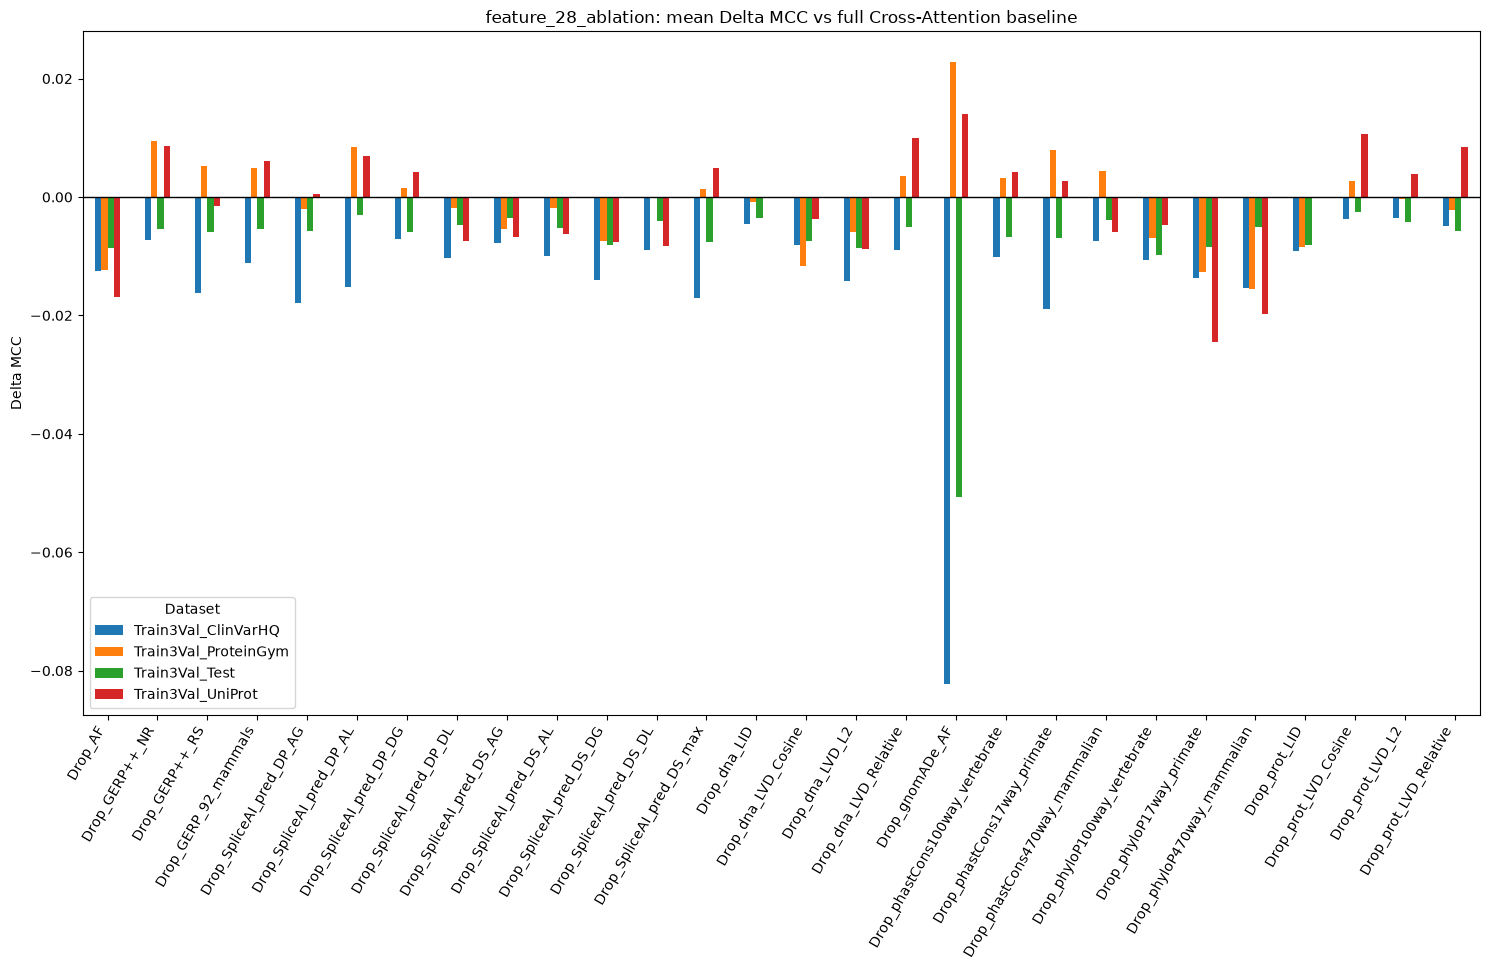

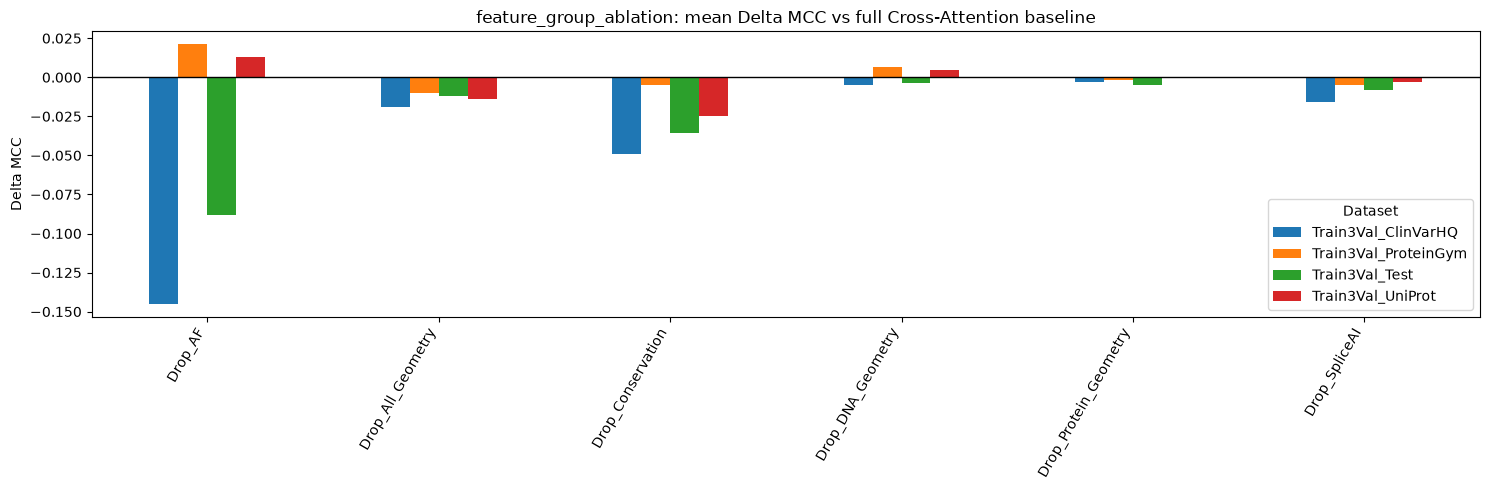

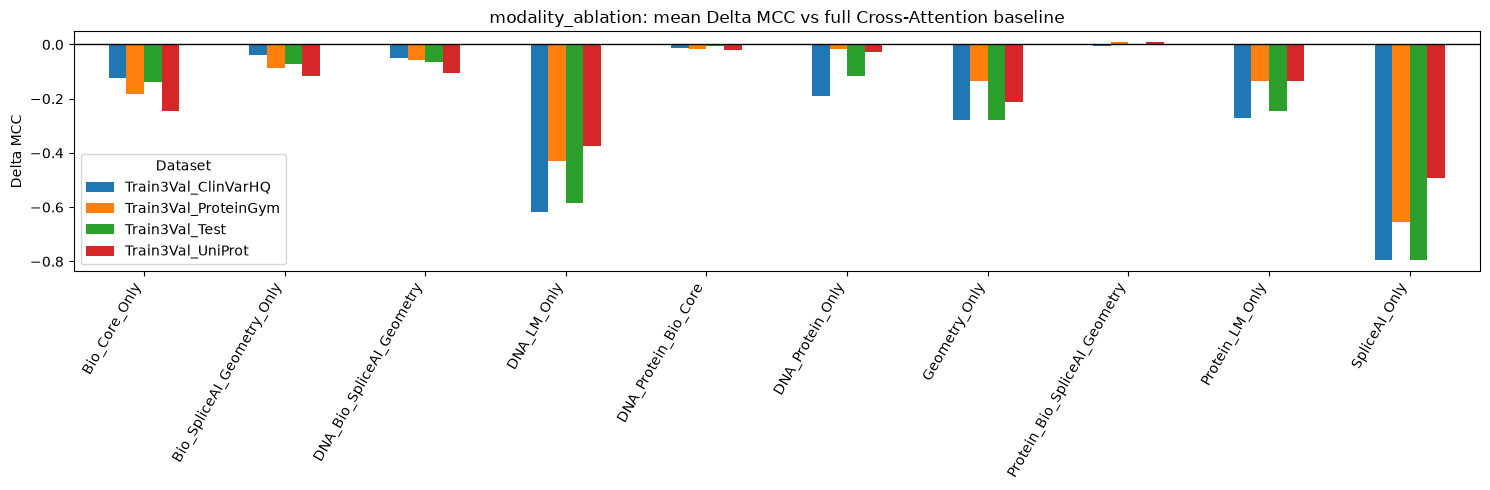

,Run_ID,Branch,Evaluation_Split,Target_Config,Ablation,Dataset,Pooling,DNA_Model,Prot_Model,Network,...,Legacy_Parameter_Val_MCC,Classifier_XGB_Model_Mem_MB,Classifier_Tree_Leaves,Classifier_GFLOPs_Note,Classifier_Model_Mem_Scope,Batch_Size,Study,Condition,PCA,PCA_Mode
1,fusion_classifier_benchmark_20261120_192605,DL,test,B_with_geometry,bio_core_dna_prot_spliceai_geom,Train3Val_ClinVarHQ,center,nt_v1_500m_dna_1001,esm1b_650m_prot_501,CrossAttention_ThreeModalities,...,NaN,NaN,NaN,NaN,NaN,64.0,baseline,All_28_All_Modalities,NaN,NaN
5,fusion_classifier_benchmark_20261120_192605,DL,test,B_with_geometry,bio_core_dna_prot_spliceai_geom,Train3Val_ClinVarHQ,center,nt_v1_500m_dna_1001,esm1b_650m_prot_501,CrossAttention_ThreeModalities,...,NaN,NaN,NaN,NaN,NaN,64.0,baseline,All_28_All_Modalities,NaN,NaN
9,fusion_classifier_benchmark_20261120_192605,DL,test,B_with_geometry,bio_core_dna_prot_spliceai_geom,Train3Val_ClinVarHQ,center,nt_v1_500m_dna_1001,esm1b_650m_prot_501,CrossAttention_ThreeModalities,...,NaN,NaN,NaN,NaN,NaN,64.0,baseline,All_28_All_Modalities,NaN,NaN
13,fusion_classifier_benchmark_20261120_192605,DL,test,B_with_geometry,bio_core_dna_prot_spliceai_geom,Train3Val_ClinVarHQ,center,nt_v1_500m_dna_1001,esm1b_650m_prot_501,CrossAttention_ThreeModalities,...,NaN,NaN,NaN,NaN,NaN,64.0,baseline,All_28_All_Modalities,NaN,NaN
17,fusion_classifier_benchmark_20261120_192605,DL,test,B_with_geometry,bio_core_dna_prot_spliceai_geom,Train3Val_ClinVarHQ,center,nt_v1_500m_dna_1001,esm1b_650m_prot_501,CrossAttention_ThreeModalities,...,NaN,NaN,NaN,NaN,NaN,64.0,baseline,All_28_All_Modalities,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
987,cross_attention_ablation_20261121_155305,Pure_ML,NaN,B_with_geometry,NaN,Train3Val_UniProt,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,pure_ml_pca,PCA,True,PCA
995,cross_attention_ablation_20261121_155305,Pure_ML,NaN,B_with_geometry,NaN,Train3Val_UniProt,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,pure_ml_pca,PCA,True,PCA
1003,cross_attention_ablation_20261121_155305,Pure_ML,NaN,B_with_geometry,NaN,Train3Val_UniProt,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,pure_ml_pca,PCA,True,PCA
1011,cross_attention_ablation_20261121_155305,Pure_ML,NaN,B_with_geometry,NaN,Train3Val_UniProt,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,pure_ml_pca,PCA,True,PCA


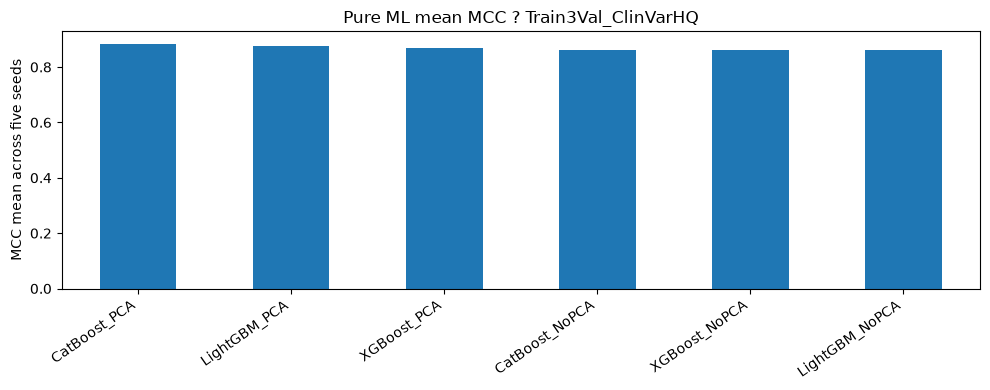

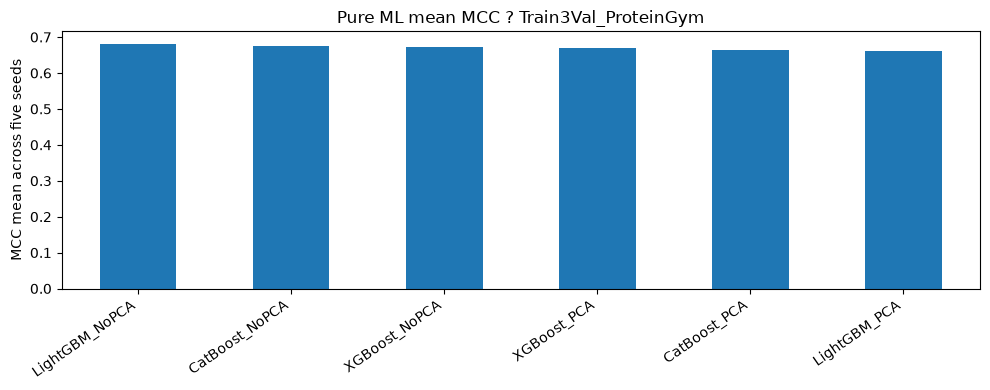

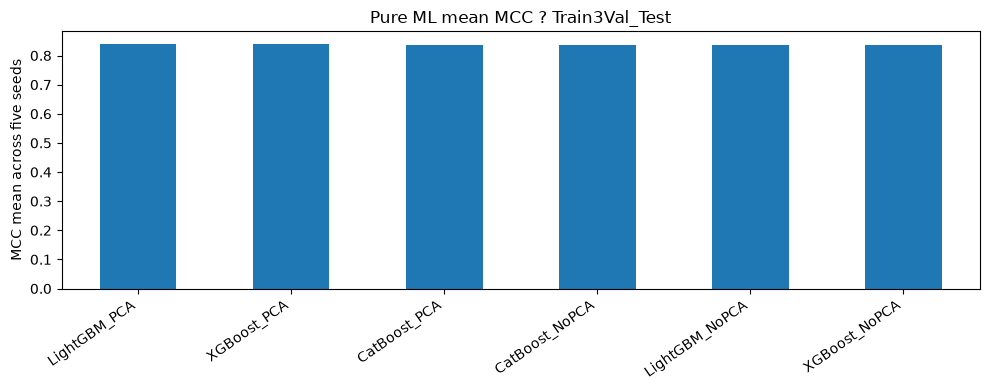

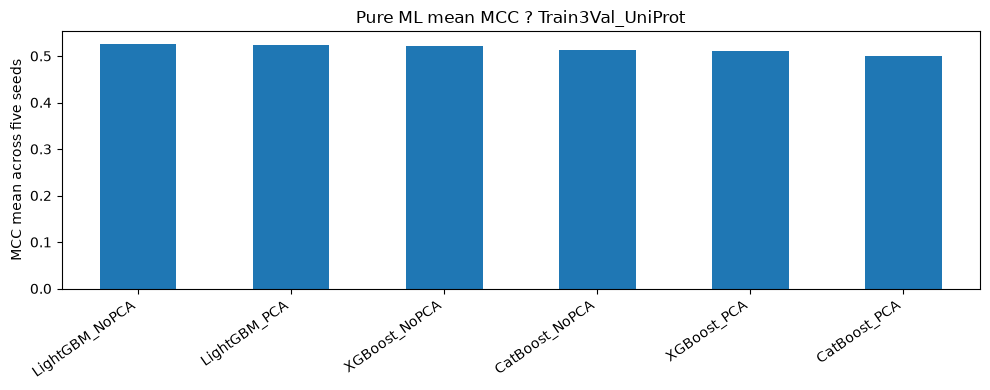

Global test metrics: D:\Missense_variant_pathogenicity_prediction\experiments\cross_attention_ablation_20261121_155305\module06_architecture_experiments\summaries\global_test_metrics_by_seed.csv
Summary output: D:\Missense_variant_pathogenicity_prediction\experiments\cross_attention_ablation_20261121_155305\module06_architecture_experiments\summaries


In [7]:
from pathlib import Path

summary_root = MODULE06_OUTPUT_ROOT / "summaries"
summary_root.mkdir(parents=True, exist_ok=True)

pure_path = MODULE06_OUTPUT_ROOT / "pure_ml_pca" / "test_metrics_by_seed.csv"
pure = pd.read_csv(pure_path) if pure_path.is_file() else pd.DataFrame()
group_path = MODULE06_OUTPUT_ROOT / "feature_group_ablation" / "delta_vs_baseline_by_seed.csv"
feature_path = MODULE06_OUTPUT_ROOT / "feature_28_ablation" / "delta_vs_baseline_by_seed.csv"
modality_path = MODULE06_OUTPUT_ROOT / "modality_ablation" / "delta_vs_baseline_by_seed.csv"
group_delta = pd.read_csv(group_path) if group_path.is_file() else pd.DataFrame()
feature_delta = pd.read_csv(feature_path) if feature_path.is_file() else pd.DataFrame()
modality_delta = pd.read_csv(modality_path) if modality_path.is_file() else pd.DataFrame()

if not pure.empty:
    pure_summary = pure.groupby(["Classifier", "PCA_Mode", "Dataset"], dropna=False)[
        ["Accuracy", "F1_Score", "MCC", "AUROC", "AUPRC"]
    ].agg(["mean", "std", "count"])
    pure_summary.columns = [f"{metric}_{stat}" for metric, stat in pure_summary.columns]
    pure_summary = pure_summary.reset_index()
    pure_summary.to_csv(summary_root / "pure_ml_mean_std_by_classifier_pca_dataset.csv", index=False)
    display(pure_summary.sort_values(["Dataset", "MCC_mean"], ascending=[True, False]))

all_delta = pd.concat(
    [frame for frame in (group_delta, feature_delta, modality_delta) if not frame.empty],
    ignore_index=True,
) if any(not frame.empty for frame in (group_delta, feature_delta, modality_delta)) else pd.DataFrame()
if not all_delta.empty:
    all_delta.to_csv(summary_root / "cross_attention_ablation_delta_by_seed.csv", index=False)
    delta_summary = all_delta.groupby(["Study", "Condition", "Dataset"], dropna=False)[
        ["MCC", "AUROC", "Baseline_MCC", "Baseline_AUROC", "Delta_MCC", "Delta_AUROC"]
    ].agg(["mean", "std", "count"])
    delta_summary.columns = [f"{metric}_{stat}" for metric, stat in delta_summary.columns]
    delta_summary = delta_summary.reset_index()
    delta_summary.to_csv(summary_root / "cross_attention_ablation_delta_mean_std.csv", index=False)
    display(delta_summary.sort_values(["Study", "Dataset", "Delta_MCC_mean"], ascending=[True, True, False]))

if not all_delta.empty:
    plot_data = all_delta.groupby(["Study", "Condition", "Dataset"], dropna=False)["Delta_MCC"].mean().reset_index()
    for study_name, frame in plot_data.groupby("Study"):
        pivot = frame.pivot(index="Condition", columns="Dataset", values="Delta_MCC")
        ax = pivot.plot(kind="bar", figsize=(15, max(5, 0.35 * len(pivot))))
        ax.axhline(0, color="black", linewidth=1)
        ax.set_title(f"{study_name}: mean Delta MCC vs full Cross-Attention baseline")
        ax.set_ylabel("Delta MCC")
        ax.set_xlabel("")
        plt.xticks(rotation=60, ha="right")
        plt.tight_layout()
        plt.show()


# One per-run global table combines all available rows without averaging models together.
cross_attention_parts = []
for study_name in ("feature_group_ablation", "feature_28_ablation", "modality_ablation"):
    metric_path = MODULE06_OUTPUT_ROOT / study_name / "test_metrics_by_seed.csv"
    if metric_path.is_file():
        frame = pd.read_csv(metric_path)
        if not frame.empty:
            cross_attention_parts.append(frame)
baseline_global = BASELINE_TEST.copy()
baseline_global["Study"] = "baseline"
baseline_global["Condition"] = "All_28_All_Modalities"
baseline_global["Architecture"] = "CrossAttention_ThreeModalities"
baseline_global["Branch"] = "DL"
pure_global = pure.copy()
if not pure_global.empty:
    pure_global["Branch"] = "Pure_ML"
    pure_global["Study"] = "pure_ml_pca"
    pure_global["Condition"] = pure_global["PCA_Mode"]
    pure_global["Architecture"] = pure_global["Classifier"]
global_frames = [baseline_global, *cross_attention_parts]
if not pure_global.empty:
    global_frames.append(pure_global)
global_metrics = pd.concat(global_frames, ignore_index=True, sort=False)
global_metrics.to_csv(summary_root / "global_test_metrics_by_seed.csv", index=False)
display(global_metrics.sort_values(["Dataset", "Study", "Condition", "Seed"]))

if not pure.empty:
    pure_plot = pure_summary.copy()
    pure_plot["Model"] = pure_plot["Classifier"].astype(str) + "_" + pure_plot["PCA_Mode"].astype(str)
    for dataset_name, frame in pure_plot.groupby("Dataset"):
        ax = frame.set_index("Model")["MCC_mean"].sort_values(ascending=False).plot(
            kind="bar", figsize=(10, 4), title=f"Pure ML mean MCC ? {dataset_name}"
        )
        ax.set_ylabel("MCC mean across five seeds")
        ax.set_xlabel("")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()

print("Global test metrics:", summary_root / "global_test_metrics_by_seed.csv")
print("Summary output:", summary_root)
